<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [NTFS $MFT Forensic Timeline](https://github.com/Query-farm/vgi-mft)

Turn a collected NTFS $MFT into a SQL forensic timeline with full paths, timestomp flags, deleted records, and data streams.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-mft/blob/main/notebooks/02_trace_one_entry_from_header_to_attributes.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-mft/blob/main/notebooks/README.md)


## Trace one entry from its header to names and attributes

Why can one MFT record produce two names and two data streams? Start with a specific entry in the same **authored synthetic fixture** as the scope notebook, retain header and validation results, then inspect the nested record and its attribute rows. Two deliberately invalid probes keep unavailable records distinct from a valid record with an empty list.

Nothing here is a live volume or incident collection. The fixture's names, contents and timestamps are invented; successful decoding does not establish chain of custody, malicious intent or a verified filesystem path.

### Choose an entry, keeping the controls fixed

`ENTRY=22` selects `notes.txt`, authored with Win32 and DOS names plus an alternate stream. Change only `ENTRY` to **25** to inspect `orphan.dat`: its parent reference is absent from the fixture. The entire timeline stays fixed. This example accepts only those two known non-directory entries so both comparisons have interpretable returned data.

Slot **1** is zero-filled and index **26** is just beyond this fixture's 26 slots. They are diagnostic controls, not extra files in the selected population. These slot facts come from the fixture generator; they are not assumptions about arbitrary MFT images.

In [1]:
ENTRY = 22  # change to 25 to inspect the authored orphan

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.17":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.17"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, prepare, theme
from IPython.display import Markdown, display
check_runtime()
prepare("mft")
import mft_example as example
example.verify_fixture()
example.validate_entry(ENTRY)
connection = connect(globals())
theme()

### Materialize the bytes and the complete timeline

The same hash-verified 26,624-byte fixture is read locally. `read_mft` returns decoded records, not one row per physical slot. Store the source BLOB once for the column-argument scalars and relation-input fan-out functions. The literal release location needs no source checkout or Rust build.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'mft' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-mft@v0.4.0');
CREATE TABLE input_bytes AS SELECT content AS blob FROM read_blob('fixtures/sample.mft');
CREATE TABLE decoded AS SELECT * FROM mft.main.read_mft('fixtures/sample.mft');
CREATE TABLE target AS SELECT * FROM decoded WHERE entry={{ENTRY}};

,Count


In [5]:
%%sql
SELECT octet_length(blob) AS source_bytes,sha256(blob) AS source_sha256,
 (SELECT count(*) FROM decoded) AS decoded_records,
 (SELECT count(*) FROM decoded WHERE is_dir) AS directories,
 (SELECT count(*) FROM decoded WHERE is_deleted) AS deleted_records
FROM input_bytes;

,source_bytes,source_sha256,decoded_records,directories,deleted_records
0,26624,6f9485acb24435636ad8207552b56f24bd9a9ca2f3dcfe...,10,3,1


### A header is a projection; validation has its own result

`record_header` supplies signature, sequence, allocation flags and record sizes without decoding attributes. `well_formed` separately checks the record and returns a reason. Keep both outcomes, including NULL headers. The out-of-range probe's `truncated` kind describes that requested index; it does not establish that this deliberately bounded fixture was collected incompletely.

Full decoding returns a STRUCT for the selected valid entry. Empty or unavailable probes return NULL, rather than a zero-attribute record. These controls exercise two specific invalid cases, not all corruption classes.

In [6]:
%%sql
CREATE TABLE probes AS
SELECT role,entry,mft.main.record_header(blob,entry) AS header,
 mft.main.well_formed(blob,entry) AS validity,
 mft.main.mft_record(blob,entry) AS record
FROM input_bytes CROSS JOIN (
 VALUES ('selected',{{ENTRY}}::UBIGINT),('zero-filled slot',1::UBIGINT),('past end',26::UBIGINT)
) AS p(role,entry);

,Count


In [7]:
%%sql probe_results <<
SELECT role,entry,header.signature AS signature,header.sequence AS sequence,
 header.in_use AS allocated,header.used_size AS used_record_bytes,
 header.allocated_size AS allocated_record_bytes,
 validity.ok AS valid_record,validity.kind AS validation_kind,validity.error AS reason,
 record IS NOT NULL AS decoded_record
FROM probes ORDER BY entry;

In [8]:
display(probe_results)
valid = int(probe_results.valid_record.sum())
missing = int(probe_results.signature.isna().sum())
display(Markdown(f"**{valid} of {len(probe_results)} probes** decode a valid record; **{missing}** have no header. Only the selected entry is the analytical subject. The controls remain explicit invalid results, not files with zero attributes."))

,role,entry,signature,sequence,allocated,used_record_bytes,allocated_record_bytes,valid_record,validation_kind,reason,decoded_record
0,zero-filled slot,1,None,<NA>,<NA>,<NA>,<NA>,False,not-an-mft,empty (zeroed) slot,False
1,selected,22,FILE,1,True,468,1024,True,ok,None,True
2,past end,26,None,<NA>,<NA>,<NA>,<NA>,False,truncated,entry index out of range,False


**1 of 3 probes** decode a valid record; **2** have no header. Only the selected entry is the analytical subject. The controls remain explicit invalid results, not files with zero attributes.

### Names are not a count of files, and paths can remain unresolved

Expand the nested `mft_record.fn` list to preserve every namespace name and its parent reference. The scalar `full_path` walks that reference graph independently; compare it with the timeline path and retain its diagnostic. A DOS short name and a Win32 name can name the same record. Neither the number of name rows nor a slash-separated reconstruction certifies distinct files or a live location.

For the orphan experiment, the missing parent remains visible as `\$Orphan` and `orphan-parent`; no parent or path is invented. Record header sizes describe the FILE record, not the content length of its streams.

In [9]:
%%sql identity <<
SELECT t.entry,t.file_name,t.full_path AS timeline_path,
 mft.main.full_path(b.blob,t.entry) AS scalar_path,t.diagnostics,
 p.record.sequence AS sequence,p.record.hard_links AS declared_hard_links,
 len(p.record.fn) AS name_rows,len(p.record.ads) AS alternate_streams,
 len(p.record.attributes) AS attribute_rows
FROM target t CROSS JOIN input_bytes b JOIN probes p ON p.entry=t.entry AND p.role='selected';

In [10]:
%%sql names <<
SELECT n.name,n.namespace,n.parent_entry,n.parent_seq,
 n.created AS fn_created_utc,n.logical_size AS filename_cached_logical_bytes
FROM probes p,unnest(p.record.fn) AS f(n)
WHERE p.role='selected' ORDER BY n.namespace,n.name;

In [11]:
display(identity)
display(names)
r = identity.iloc[0]
diagnostic = r.diagnostics if r.diagnostics is not None else "none"
display(Markdown(f"Entry **{r.entry}** has **{r.name_rows} namespace name rows**, **{r.declared_hard_links} declared hard link(s)** and **{r.alternate_streams} alternate stream(s)**. Both path projections agree: **{r.timeline_path == r.scalar_path}**. Path diagnostic: **{diagnostic}**. Name rows stay separate from the record and link counts."))

,entry,file_name,timeline_path,scalar_path,diagnostics,sequence,declared_hard_links,name_rows,alternate_streams,attribute_rows
0,22,notes.txt,Windows\System32\notes.txt,Windows\System32\notes.txt,None,1,1,2,1,5


,name,namespace,parent_entry,parent_seq,fn_created_utc,filename_cached_logical_bytes
0,NOTES~1.TXT,DOS,12,1,2020-09-13 12:26:40.500,5
1,notes.txt,Win32,12,1,2020-09-13 12:26:40.500,5


Entry **22** has **2 namespace name rows**, **1 declared hard link(s)** and **1 alternate stream(s)**. Both path projections agree: **True**. Path diagnostic: **none**. Name rows stay separate from the record and link counts.

### Account for attribute instances before joining their meanings

`attributes` fans one `(blob, entry)` input into one row per attribute. Join its type ID to `ntfs_attribute_types`, the worker's fixed reference view, to distinguish standard information, file names and data content. Unknown IDs would keep their row through the LEFT JOIN. The reference explains the returned types; it is not evidence that every listed type occurred.

The chart counts **attribute instances in one selected record**. The table also reports logical attribute-value bytes; their sum is not a file's content size. Metadata attributes carry bytes too. Use the separate `streams` projection for primary/alternate data and available resident bytes. Non-resident content, if present, would remain NULL; no cluster read is performed.

In [12]:
%%sql
CREATE TABLE attribute_rows AS
SELECT * FROM mft.main.attributes((SELECT blob,{{ENTRY}}::UBIGINT AS entry FROM input_bytes));
CREATE TABLE stream_rows AS
SELECT * FROM mft.main.streams((SELECT blob,{{ENTRY}}::UBIGINT AS entry FROM input_bytes));

,Count


In [13]:
%%sql attribute_summary <<
SELECT a.type_id,a.type_name AS decoded_type,coalesce(t.type_name,'[unlisted type]') AS reference_type,
 t.purpose,count(*) AS instances,count(*) FILTER(WHERE a.resident) AS resident_instances,
 sum(a.logical_size) AS logical_attribute_value_bytes
FROM attribute_rows a LEFT JOIN mft.main.ntfs_attribute_types t USING(type_id)
GROUP BY ALL ORDER BY a.type_id;

In [14]:
%%sql streams <<
SELECT entry,name AS stream_name,resident,logical_size AS logical_content_bytes,
 octet_length(data) AS available_resident_bytes
FROM stream_rows ORDER BY name NULLS FIRST;

,type_id,decoded_type,reference_type,purpose,instances,resident_instances,logical_attribute_value_bytes
0,16,$STANDARD_INFORMATION,$STANDARD_INFORMATION,Standard information: the SI MACB timestamp qu...,1,1,72.0
1,48,$FILE_NAME,$FILE_NAME,"A name (Win32, DOS 8.3, or POSIX namespace), t...",2,2,172.0
2,128,$DATA,$DATA,File content: the unnamed primary stream plus ...,2,2,18.0


,entry,stream_name,resident,logical_content_bytes,available_resident_bytes
0,22,None,True,5,5
1,22,hidden,True,13,13


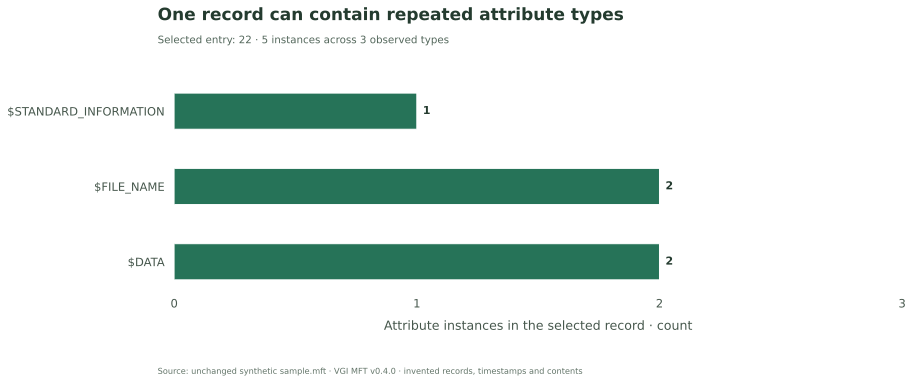

The selected record fans out to **5 attribute instances** across **3 observed types**. Its **2 data streams** expose **18 resident content bytes**. Those are three different denominators: attribute instances, streams and content bytes.

In [15]:
display(attribute_summary)
display(streams)
example.attributes(attribute_summary, ENTRY)
attrs = int(attribute_summary.instances.sum())
bytes_present = int(streams.available_resident_bytes.sum())
display(Markdown(f"The selected record fans out to **{attrs} attribute instances** across **{len(attribute_summary)} observed types**. Its **{len(streams)} data streams** expose **{bytes_present} resident content bytes**. Those are three different denominators: attribute instances, streams and content bytes."))

### Reconcile the projections within their scopes

The checks compare the scalar record with its header and timeline, count nested names and attributes, and reconcile data attributes with stream rows. They explicitly preserve the two invalid controls. Agreement among projections checks this example's accounting; it does not independently validate a live disk or the truth of authored metadata.

In [16]:
%%sql checks <<
SELECT 'one selected decoded record' AS check_name,count(*)=1 AS passed FROM target
UNION ALL SELECT 'selected header and record sequence agree',bool_and(header.sequence=record.sequence) FROM probes WHERE role='selected'
UNION ALL SELECT 'selected record passes validation',bool_and(validity.ok AND record IS NOT NULL) FROM probes WHERE role='selected'
UNION ALL SELECT 'control failures retain reason and missing record',bool_and(NOT validity.ok AND validity.error IS NOT NULL AND record IS NULL AND header IS NULL) FROM probes WHERE role<>'selected'
UNION ALL SELECT 'zero-filled slot classified separately',bool_and(validity.kind='not-an-mft') FROM probes WHERE role='zero-filled slot'
UNION ALL SELECT 'past-end index classified separately',bool_and(validity.kind='truncated') FROM probes WHERE role='past end'
UNION ALL SELECT 'scalar path matches timeline',bool_and(mft.main.full_path(b.blob,t.entry)=t.full_path) FROM target t CROSS JOIN input_bytes b
UNION ALL SELECT 'nested attribute count matches fan-out',len(record.attributes)=(SELECT count(*) FROM attribute_rows) FROM probes WHERE role='selected'
UNION ALL SELECT 'data attribute count matches streams',(SELECT count(*) FROM attribute_rows WHERE type_id=128)=(SELECT count(*) FROM stream_rows)
UNION ALL SELECT 'file-name attribute count matches names',len(record.fn)=(SELECT count(*) FROM attribute_rows WHERE type_id=48) FROM probes WHERE role='selected'
UNION ALL SELECT 'alternate stream count matches names',len(record.ads)=(SELECT count(*) FROM stream_rows WHERE name IS NOT NULL) FROM probes WHERE role='selected'
UNION ALL SELECT 'resident data bytes reconcile',bool_and(data IS NOT NULL AND octet_length(data)=logical_size) FROM stream_rows WHERE resident;

In [17]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all()
display(Markdown(f"All **{len(checks)} relationship checks** pass. Invalid controls remain missing records; the selected record's names, attributes and streams reconcile without treating their row counts as interchangeable."))

,check_name,passed
0,one selected decoded record,True
1,selected header and record sequence agree,True
2,selected record passes validation,True
3,control failures retain reason and missing record,True
4,zero-filled slot classified separately,True
5,past-end index classified separately,True
6,scalar path matches timeline,True
7,nested attribute count matches fan-out,True
8,data attribute count matches streams,True
9,file-name attribute count matches names,True


All **12 relationship checks** pass. Invalid controls remain missing records; the selected record's names, attributes and streams reconcile without treating their row counts as interchangeable.

### Try one change

Change `ENTRY` from **22** to **25**, then restart and run all into a separate experiment destination. Predict how name count, attribute instances and resident content bytes change. The selected record should remain valid while its parent path becomes unresolved. The complete timeline, fixture hash and two invalid probes stay unchanged. Restore **22** for the saved default.

In [18]:
connection.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-mft](https://github.com/Query-farm/vgi-mft)